# imports

In [5]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [6]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [7]:
# specific

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils
# sys.path.append(os.path.join(os.getcwd(), '../../../fly-control/src'))
# from utils_fly_control import read_utils as read_utils_control

In [9]:
importlib.reload(read_utils)
# importlib.reload(read_utils_control)

<module 'utils_fly.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/notebooks/analysis/../../src/utils_fly/read_utils.py'>

# setup

In [10]:
ll = 'll00'
data_variant = 'gcamp'

save = True

In [11]:
# specific

model_variant = 'ns'
organism = 'fly'
manual = True
full = False

In [12]:
file_id = 0

# load

In [13]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filename = analysis_utils.read_filename(organism, file_id)
metadata = (filename, model_path, model_variant, data_variant, manual, full)

# scores

In [14]:
((bom_spn, _, _, _, _, _, _),
 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_predictions(*metadata)

neuron_scores = analysis_utils.assemble_scoress([bom_spn], [hgm_spn])

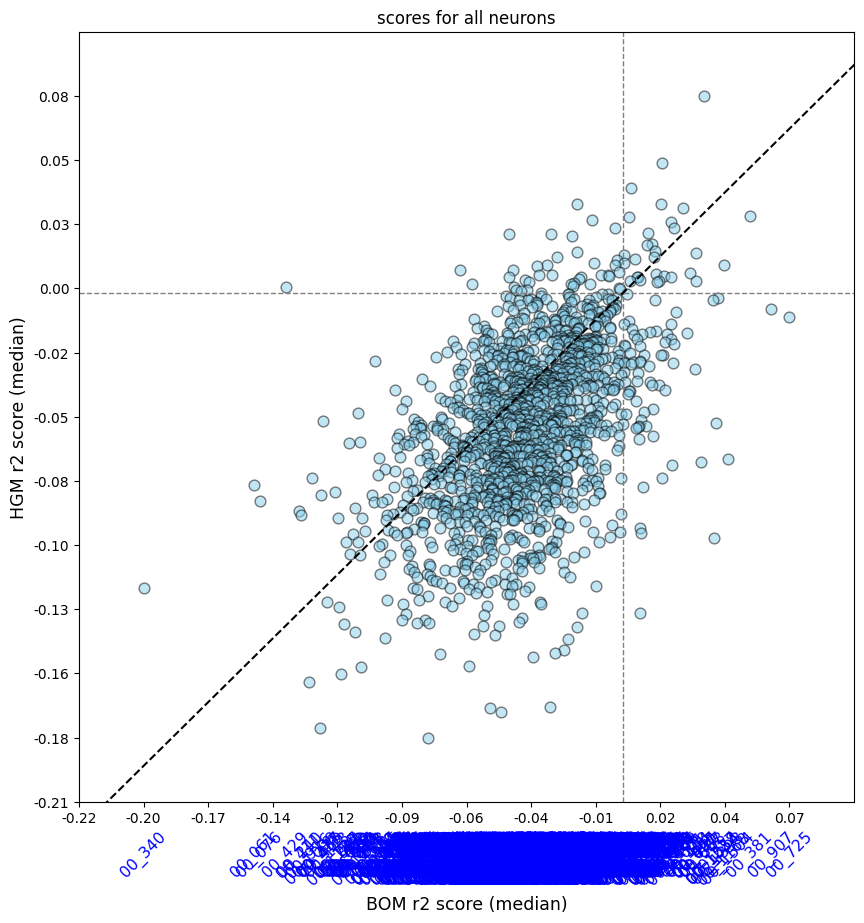

In [15]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=None,
	save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_all' if save else None
)

In [16]:
if organism == 'worm':
	plot_utils.plot_performance_plot(
		{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()}, None,
		title='scores for ID\'d neurons', limits=None,
		save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_id' if save else None
	)

In [17]:
print(f'\'{'\', \''.join([neuron_label for neuron_label in list(neuron_scores.keys())[:10]])}\'')

'00_568', '00_521', '00_137', '00_1370', '00_656', '00_601', '00_381', '00_700', '00_426', '00_843'


# shuffle control

In [ ]:
shuffles = sum(folder.startswith('shuffle_') for folder in os.listdir(os.path.join(read_utils_control.get_model_path(0), '..'))) - 1

In [ ]:
boms_spn, hgms_spn = list(), list()
for shuffle_id in range(shuffles):
	((bom_spn, _, _, _, _, _, _),
	 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(filename, read_utils_control.get_model_path(shuffle_id), model_variant, data_variant, manual, full)
	boms_spn.append(bom_spn)
	hgms_spn.append(hgm_spn)

neuron_scores_shuffle = analysis_utils.assemble_scoress(boms_spn, hgms_spn)

In [ ]:
plot_utils.plot_performance_plot(
	neuron_scores, neuron_scores_shuffle,
	title='scores for all neurons (+control)', limits=None,
	horizontal_bps=False, force_medians=False,
	save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_id_control' if save else None
)

In [ ]:
# compute HGM percentiles
percentiles_hgm = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='hgm'
)

# compute BOM percentiles
percentiles_bom = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='bom'
)

In [ ]:
ai_slob.plot_percentile_hist(percentiles_hgm,
							 title='HGM percentiles', threshold=100, bins=shuffles,
							 save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_hgm_percentiles' if save else None)

In [ ]:
significant_neurons = {key: value for key, value in neuron_scores.items() if percentiles_hgm[key] >= 100.0}
significant_neurons = dict(sorted(significant_neurons.items(), key=lambda x: x[1][1], reverse=True))  #  - x[1][0]

In [ ]:
os.makedirs(f'../../out/data/significant_neurons/{filename}/', exist_ok=True)
pd.DataFrame(significant_neurons).to_csv(f'../../out/data/significant_neurons/{filename}/{model_variant}_model.csv')

In [ ]:
ai_slob.plot_control_histograms(neuron_scores, neuron_scores_shuffle, list(significant_neurons.keys())[:50],
								save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_neurons' if save else None)
pass

In [ ]:
print(f'\'{'\', \''.join([neuron_label for neuron_label in significant_neurons.keys()])}\'')

In [ ]:
print(f'\'{'\', \''.join([neuron_label for neuron_label in significant_neurons.keys() if not neuron_label[0].isdigit()])}\'')